# Quick baseline: race pace with linear regression

Small sketch of the pipeline (ingest → preprocess → train → evaluate) on a few 2024 races. It is only meant to see how a simple model behaves and to set a first baseline, not to be the real pipeline.

- **Target:** `race_pace_delta_pct` = (driver's median clean lap / field's median clean lap − 1) × 100. Negative = faster than the field.
- **Features (all known on Saturday):** `quali_delta_pct`, `grid_position`, `reached_q3`, `track_temp` (qualifying session) and `driver_pace_last3` (form, previous races only).
- **Split:** temporal. First 8 rounds train, rounds 9–12 test.

In [1]:
import warnings
import numpy as np
import pandas as pd
import fastf1
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
fastf1.set_log_level("ERROR")
import os
os.makedirs(".fastf1_cache", exist_ok=True)
fastf1.Cache.enable_cache(".fastf1_cache")

YEAR, ROUNDS, N_TRAIN = 2024, range(1, 13), 8

## 1. Ingestion and preprocessing (one row = one driver in one race)

In [2]:
def race_rows(year, rnd):
    # Qualifying: Saturday features
    q = fastf1.get_session(year, rnd, "Q")
    q.load(laps=False, telemetry=False, weather=True, messages=False)
    res = q.results.copy()
    best = res[["Q1", "Q2", "Q3"]].min(axis=1).dt.total_seconds()
    pole = best.min()
    feats = pd.DataFrame({
        "driver": res["Abbreviation"],
        "team": res["TeamName"],
        "quali_delta_pct": (best / pole - 1) * 100,
        "grid_position": res["Position"],
        "reached_q3": res["Q3"].notna().astype(int),
    })
    feats["track_temp"] = q.weather_data["TrackTemp"].mean()

    # Race: target (Sunday data is used ONLY for the target)
    r = fastf1.get_session(year, rnd, "R")
    r.load(laps=True, telemetry=False, weather=False, messages=False)
    laps = r.laps
    clean = laps[(laps["LapNumber"] > 1) & laps["PitInTime"].isna() & laps["PitOutTime"].isna()
                 & (laps["TrackStatus"] == "1") & laps["LapTime"].notna()].copy()
    clean["lap_s"] = clean["LapTime"].dt.total_seconds()
    field_median = clean["lap_s"].median()
    g = clean.groupby("Driver")["lap_s"].agg(["median", "count"])
    g = g[g["count"] >= 10]  # valid-row rule: at least 10 clean laps
    target = ((g["median"] / field_median - 1) * 100).rename("race_pace_delta_pct")

    out = feats.merge(target, left_on="driver", right_index=True)  # drops drivers without a valid target
    out.insert(0, "round", rnd)
    return out

df = pd.concat([race_rows(YEAR, rnd) for rnd in ROUNDS], ignore_index=True).dropna(subset=["quali_delta_pct"])

# Transformation: wet or red-flagged qualifying produces extreme gaps (up to ~15%), so cap the feature at 3%
df["quali_delta_pct"] = df["quali_delta_pct"].clip(upper=3)

# Form feature: mean target of the driver's previous 3 races (never includes the current race)
df = df.sort_values(["driver", "round"])
df["driver_pace_last3"] = (df.groupby("driver")["race_pace_delta_pct"]
                             .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean()))
df = df.sort_values(["round", "grid_position"]).reset_index(drop=True)
print(df.shape)
df.head()

(226, 9)


,round,driver,team,quali_delta_pct,grid_position,reached_q3,track_temp,race_pace_delta_pct,driver_pace_last3
0,1,VER,Red Bull Racing,0.015701,1.0,1,21.514286,-1.483283,NaN
1,1,LEC,Ferrari,0.000000,2.0,1,21.514286,-0.092931,NaN
2,1,RUS,Mercedes,0.358885,3.0,1,21.514286,-0.419222,NaN
3,1,SAI,Ferrari,0.383559,4.0,1,21.514286,-0.766165,NaN
4,1,PER,Red Bull Racing,0.417204,5.0,1,21.514286,-0.655680,NaN


In [3]:
FEATURES = ["quali_delta_pct", "grid_position", "reached_q3", "track_temp", "driver_pace_last3"]
TARGET = "race_pace_delta_pct"

print("Missing values per feature:")
print(df[FEATURES + [TARGET]].isna().sum().to_string())
df[FEATURES + [TARGET]].corr()[TARGET].round(2).to_frame("corr with target")

Missing values per feature:
quali_delta_pct         0
grid_position           0
reached_q3              0
track_temp              0
driver_pace_last3      21
race_pace_delta_pct     0


,corr with target
quali_delta_pct,0.76
grid_position,0.80
reached_q3,-0.73
track_temp,-0.03
driver_pace_last3,0.73
race_pace_delta_pct,1.00


## 2. Temporal split

In [4]:
train = df[df["round"] <= N_TRAIN]
test = df[df["round"] > N_TRAIN]
print(f"train: {len(train)} rows (rounds 1-{N_TRAIN}) | test: {len(test)} rows (rounds {N_TRAIN + 1}-{max(ROUNDS)})")

train: 147 rows (rounds 1-8) | test: 79 rows (rounds 9-12)


## 3. Training
Three references: the training mean, a qualifying-only baseline and linear regression with all features (imputation and scaling inside the pipeline).

In [5]:
models = {
    "mean (naive)": None,
    "baseline: qualifying only": make_pipeline(LinearRegression()),
    "linear regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
}
cols = {"baseline: qualifying only": ["quali_delta_pct"], "linear regression": FEATURES}

preds = {}
for name, model in models.items():
    if model is None:
        preds[name] = np.full(len(test), train[TARGET].mean())
    else:
        model.fit(train[cols[name]], train[TARGET])
        preds[name] = model.predict(test[cols[name]])

## 4. Evaluation

In [6]:
def pairwise_accuracy(frame, pred):
    # share of driver pairs, within the same race, whose pace order the model gets right
    ok = total = 0
    for _, idx in frame.groupby("round").indices.items():
        y, p = frame[TARGET].to_numpy()[idx], pred[idx]
        dy, dp = y[:, None] - y[None, :], p[:, None] - p[None, :]
        mask = np.triu(np.ones_like(dy, dtype=bool), 1) & (dy != 0)
        hit = np.sign(dy[mask]) == np.sign(dp[mask])
        ok += hit.sum() + 0.5 * (dp[mask] == 0).sum()  # ties count as chance
        total += mask.sum()
    return ok / total

rows = []
for name, p in preds.items():
    rows.append({
        "model": name,
        "MAE": mean_absolute_error(test[TARGET], p),
        "RMSE": mean_squared_error(test[TARGET], p) ** 0.5,
        "R2": r2_score(test[TARGET], p),
        "pairwise acc.": pairwise_accuracy(test.reset_index(drop=True), p),
    })
metrics = pd.DataFrame(rows).set_index("model").round(3)
metrics

,MAE,RMSE,R2,pairwise acc.
model,,,,
mean (naive),0.821,1.000,-0.005,0.500
baseline: qualifying only,0.541,0.723,0.475,0.850
linear regression,0.461,0.658,0.565,0.846


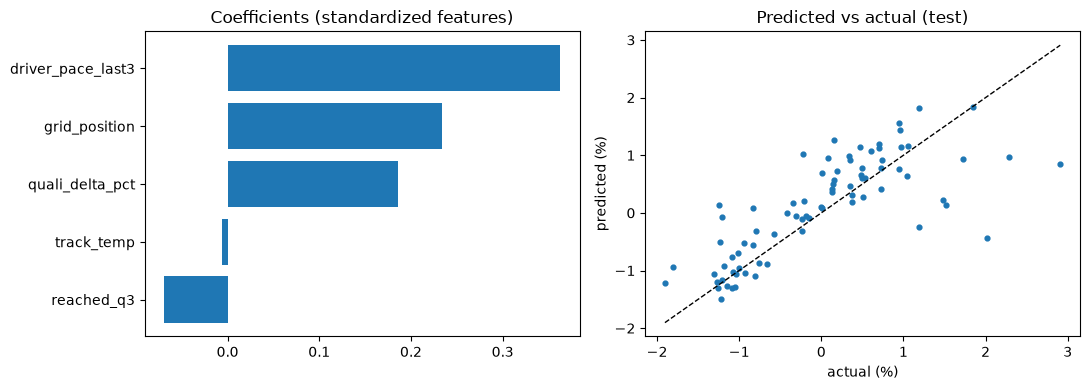

In [7]:
lr = models["linear regression"]
coefs = pd.Series(lr[-1].coef_, index=FEATURES).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh(coefs.index, coefs.values)
ax[0].set_title("Coefficients (standardized features)")
ax[1].scatter(test[TARGET], preds["linear regression"], s=12)
lim = [test[TARGET].min(), test[TARGET].max()]
ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set(title="Predicted vs actual (test)", xlabel="actual (%)", ylabel="predicted (%)")
plt.tight_layout()

## Notes

- The real MAE comparison is against the qualifying baseline (row 2). If linear regression barely improves on it, the extra features add little for this simple model.
- `quali_delta_pct` is capped at 3% because rain or red flags in qualifying (e.g. round 12) create extreme gaps that a linear model cannot extrapolate.
- This sketch uses `Position` from qualifying as the grid (it ignores grid penalties), 12 races of one season and no tuning.
- Practice features (`fp_long_run_delta_pct`, `fp_tyre_deg`) and circuit features are left out on purpose to keep it short.